# Paper figures

Four multi-panel figures for the Aug 17–18, 2024 PNW MCS paper.

1. **Near-storm environment** (WRF 1.33 km): rows = fields, columns = times, with the MCS track outline on every panel.
1.5. **WRF soundings**: Skew-T + hodograph at three site/time pairs.
2. **Supercell phase** (NEXRAD): reflectivity (top row) and velocity (bottom row) every 30 min, 21–00 UTC, with the storm reports from each bin.
3. **MCS phase** (NEXRAD): same layout, 00–04 UTC.
4. **Supercell close-up** (NEXRAD): reflectivity, velocity and correlation coefficient rows at four times.

Edit the config cells, then rerun the cells below them. Set `SAVE_FIGS` / `SHOW_FIGS` in the global config.

In [50]:
import os
import re
import warnings
from glob import glob
from datetime import datetime, date, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from netCDF4 import Dataset
from scipy.ndimage import gaussian_filter
from scipy.spatial import cKDTree
import wrf
from wrf import getvar, interplevel, to_np
import pyart
import osmnx as ox
from metpy.plots import ctables, SkewT, Hodograph
import metpy.calc as mpcalc
from metpy.units import units
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

warnings.filterwarnings('ignore', category=RuntimeWarning)
PC = ccrs.PlateCarree()

In [54]:
pd.read_csv('240817_rpts_raw_hail.csv', skiprows=1).to_csv('hail_reports_clean.csv')

## Global config

In [45]:
# ---- Output toggles ----
SAVE_FIGS = True                  # write figures to OUT_DIR
SHOW_FIGS = True                  # display figures inline (False -> close after saving)
OUT_DIR = 'publication_figures'
FORMATS = ['png', 'pdf']
DPI = 300                         # resolution of the saved files
SHOW_DPI = 150                    # resolution of the inline display (matplotlib default is 100)

# ---- Data paths ----
WRF_DIR = r"C:\Users\miles\Downloads\mcs_side_proj\unzipped_43km_data"   # 1.33 km hourly wrfout, 17/12Z-18/12Z
MASK_DIR = r"C:\Users\miles\Downloads\mcs_side_proj\mcs_masks"           # 1.33 km PyFLEXTRKR mcstracks_*.nc
TRACK_ID = 6                                                             # tracknumber of the MCS in the 1.33 km run
RADAR_DIR = './radar_files'
ENV_CACHE_DIR = r"C:\Users\miles\Downloads\mcs_side_proj\paper_fig_cache"   # computed WRF fields (CAPE etc.), one .npz per time
HAIL_CSV = '240817_rpts_raw_hail.csv'
WIND_CSV = '240817_rpts_filtered_wind.csv'

# ---- Map overlays ----
# Reference cities on the radar figures (only those inside the extent are drawn). Set to {} to turn off.
CITIES = {
    'Portland': (45.515, -122.679), 'Salem': (44.943, -123.035), 'Eugene': (44.052, -123.087),
    'Corvallis': (44.565, -123.262), 'Bend': (44.058, -121.315), 'Madras': (44.633, -121.129),
    'Vancouver': (45.639, -122.661), 'Hood River': (45.705, -121.521), 
    'Longview': (46.138, -122.938), 'Centralia': (46.716, -122.954), 'Olympia': (47.038, -122.900),
    'Tacoma': (47.253, -122.444), 'Seattle': (47.606, -122.332), 
    'Yakima': (46.602, -120.506), 'Ellensburg': (46.997, -120.548), 'Detroit': (44.734, -122.151),
    'Estacada': (45.2896, -122.3337), 'Three Lynx': (45.1262, -122.0715), 'Mt Hood Village': (45.3554, -121.9806)
}
SHOW_RIVERS = True                # Natural Earth 10m rivers on the radar figures
SHOW_COUNTIES = True              # thin county outlines on the radar figures
# OpenStreetMap lakes + rivers (much more detail than Natural Earth) for maps drawn with osm_water=True.
# This box's query is already in ./cache from radar_analysis.ipynb, so it loads offline; a different box
# needs internet the first time (the Overpass download can take minutes for big areas).
OSM_WATER_BBOX = (-122.5, 44.5, -121.75, 45.0)   # (W, S, E, N)
GRID_SUBDIVIDE = 2                # lat/lon gridlines per labeled interval (1 = a line only at each label)
SHOW_RADAR_SITES = True           # NEXRAD site markers on every map (only those inside the extent)
RADAR_SITES = {'KRTX': (45.715, -122.965), 'KLGX': (47.117, -124.107), 'KATX': (48.195, -122.496)}

## Shared helpers

In [46]:
plt.rcParams['figure.dpi'] = SHOW_DPI
NWS_REF_CMAP = ctables.registry.get_colortable('NWSReflectivity')
LETTERS = 'abcdefghijklmnopqrstuvwxyz'


def finish(fig, name):
    # Save to OUT_DIR in every format (if SAVE_FIGS), then show or close.
    if SAVE_FIGS:
        os.makedirs(OUT_DIR, exist_ok=True)
        for fmt in FORMATS:
            path = os.path.join(OUT_DIR, f'{name}.{fmt}')
            fig.savefig(path, dpi=DPI, bbox_inches='tight')
            print('saved', path)
    if SHOW_FIGS:
        plt.show()
    else:
        plt.close(fig)


def nice_step(span, max_lines=5):
    for s in [.05, .1, 0.25, 0.5, 1, 2, 5, 10]:
        if span / s <= max_lines:
            return s
    return 10


RIVERS = [cfeature.NaturalEarthFeature('physical', name, '10m', facecolor='none')
          for name in ('rivers_lake_centerlines', 'rivers_north_america')]
COUNTIES = cfeature.NaturalEarthFeature('cultural', 'admin_2_counties', '10m', facecolor='none')


_OSM_WATER = {}


def get_osm_water(bbox=OSM_WATER_BBOX):
    # OSM lakes/reservoirs (polygons) and rivers (lines) in bbox, via osmnx (cached in ./cache).
    if bbox not in _OSM_WATER:
        try:
            g = ox.features.features_from_bbox(bbox, tags={'natural': ['water'], 'waterway': ['river']})
            g = g[~g.index.duplicated()]      # the Overpass sub-queries return some features more than once
            _OSM_WATER[bbox] = g[g.geometry.type.isin(['Polygon', 'MultiPolygon', 'LineString', 'MultiLineString'])]
        except Exception as e:
            print('OSM water download failed:', e)
            _OSM_WATER[bbox] = None
    return _OSM_WATER[bbox]


def plot_osm_water(ax):
    g = get_osm_water()
    if g is None:
        return
    polys = g[g.geometry.type.isin(['Polygon', 'MultiPolygon'])]
    lines = g[g.geometry.type.isin(['LineString', 'MultiLineString'])]
    # rivers first, then lakes filled on top, so river centerlines running through reservoirs are hidden
    ax.add_geometries(lines.geometry, crs=PC, facecolor='none', edgecolor='dodgerblue', linewidth=0.7, zorder=5)
    ax.add_geometries(polys.geometry, crs=PC, facecolor='dodgerblue', edgecolor='dodgerblue', linewidth=0.5,
                      zorder=5.1)


def setup_map(ax, extent, label_left=True, label_bottom=True, fontsize=7, detail=False, osm_water=False):
    # detail=True adds rivers and county outlines (per SHOW_RIVERS / SHOW_COUNTIES);
    # osm_water=True swaps the Natural Earth rivers for OpenStreetMap lakes + rivers (OSM_WATER_BBOX).
    ax.set_extent(extent, crs=PC)
    if detail and SHOW_COUNTIES:
        ax.add_feature(COUNTIES, edgecolor='dimgray', linewidth=0.3, zorder=5)
    if detail and SHOW_RIVERS and osm_water:
        plot_osm_water(ax)
    elif detail and SHOW_RIVERS:
        for riv in RIVERS:
            ax.add_feature(riv, edgecolor='dodgerblue', linewidth=0.7, zorder=5)
    ax.add_feature(cfeature.COASTLINE.with_scale('50m'), linewidth=0.8, zorder=6)
    ax.add_feature(cfeature.STATES.with_scale('50m'), linewidth=0.5, zorder=6)
    ax.add_feature(cfeature.BORDERS.with_scale('50m'), linewidth=0.8, zorder=6)
    dx, dy = nice_step(extent[1] - extent[0]), nice_step(extent[3] - extent[2])
    fine = ax.gridlines(crs=PC, draw_labels=False, linewidth=0.4, color='gray', linestyle=':', zorder=7)
    fine.xlocator = mticker.MultipleLocator(dx / GRID_SUBDIVIDE)
    fine.ylocator = mticker.MultipleLocator(dy / GRID_SUBDIVIDE)
    gl = ax.gridlines(crs=PC, draw_labels=True, linewidth=0, x_inline=False, y_inline=False, zorder=7)
    gl.xlocator = mticker.MultipleLocator(dx)
    gl.ylocator = mticker.MultipleLocator(dy)
    gl.top_labels = gl.right_labels = False
    gl.left_labels = label_left
    gl.bottom_labels = label_bottom
    gl.xlabel_style = gl.ylabel_style = {'size': fontsize}
    gl.rotate_labels = False


def panel_label(ax, i, fontsize=9):
    ax.text(0.02, 0.98, f'({LETTERS[i % 26]})', transform=ax.transAxes, ha='left', va='top',
            fontsize=fontsize, fontweight='bold', zorder=20,
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1.5))


def plot_cities(ax, extent, fontsize=5.5, extra=None, cities=None):
    # CITIES (or a replacement dict `cities`) plus any figure-specific extras ({name: (lat, lon)}).
    for name, (lat, lon) in {**(CITIES if cities is None else cities), **(extra or {})}.items():
        if extent[0] <= lon <= extent[1] and extent[2] <= lat <= extent[3]:
            ax.plot(lon, lat, 'o', ms=2.5, mfc='white', mec='black', mew=0.6, transform=PC, zorder=11)
            east = lon > extent[1] - 0.12 * (extent[1] - extent[0])      # label to the left near the east edge
            ax.annotate(name, (lon, lat), xycoords=PC._as_mpl_transform(ax), xytext=(-3 if east else 3, 2),
                        textcoords='offset points', fontsize=fontsize, zorder=11, annotation_clip=True,
                        ha='right' if east else 'left', va='bottom',
                        bbox=dict(facecolor='white', edgecolor='none', alpha=0.6, pad=0.3))


def plot_radar_sites(ax, extent, label=True, fontsize=6):
    if not SHOW_RADAR_SITES:
        return
    for stn, (lat, lon) in RADAR_SITES.items():
        if extent[0] <= lon <= extent[1] and extent[2] <= lat <= extent[3]:
            ax.scatter(lon, lat, marker='v', s=60, facecolor='red', edgecolor='black', linewidth=0.8,
                       transform=PC, zorder=13)
            if label:
                ax.text(lon, lat - 0.06, stn, fontsize=fontsize, fontweight='bold', ha='center', va='top',
                        transform=PC, zorder=13, bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=0.4))


def parse_report_time(timestr):
    # SPC HHMM in UTC for the 12Z-12Z day: >= 1200 is Aug 17, < 1200 is Aug 18.
    timestr = str(timestr).strip().split('.')[0]
    t = datetime.strptime(timestr.zfill(4), '%H%M').time()
    day = date(2024, 8, 17) if t.hour >= 12 else date(2024, 8, 18)
    return datetime.combine(day, t)


def load_reports(hail_csv=HAIL_CSV, wind_csv=WIND_CSV):
    hail = pd.read_csv(hail_csv, skiprows=1)      # hail file has a title line above the header
    wind = pd.read_csv(wind_csv)
    hail['reporttype'] = 'Hail'
    wind['reporttype'] = 'Wind'
    for df in (hail, wind):
        df.columns = [c.lower() for c in df.columns]
    rpts = pd.concat([hail, wind], ignore_index=True).dropna(subset=['lat', 'lon', 'time'])
    rpts['datetime'] = rpts['time'].apply(parse_report_time)
    return rpts


reports = load_reports()
print(len(reports), 'reports loaded')

288 reports loaded


## Figure 1: Near-storm environment (WRF 1.33 km)

Each entry in `ENV_PANELS` is one row and each time in `ENV_TIMES` is one column. Available fields: `mucape`, `mucin`, `lcl`, `td2` (°F), `slp`, `refl`,
`th2` (K), `dth2` (1 h change in 2 m θ), `wspd10` (kt), `shr06` (0–6 km bulk shear magnitude, kt), `capeshear` (MUCAPE × shear, m³ s⁻³), `q850` (g/kg), `mf850` (850 hPa moisture flux magnitude, g kg⁻¹ m s⁻¹; NaN where 850 hPa is below ground). `quiver=(u, v)` draws arrows (e.g. `('mfu850', 'mfv850')`), with `quiver_key` giving the key arrow's length. Barb pairs: `('ushr', 'vshr')` for the 0–6 km bulk shear
and `('u10', 'v10')` for the 10 m wind, both in kt and earth-relative. `contour` draws a smoothed line field over the
shading.

In [47]:
ENV_TIMES = ['2024-08-17 18:00', '2024-08-17 21:00', '2024-08-18 00:00', '2024-08-18 03:00']
ENV_EXTENT = [-126, -118.0, 43.0, 49.0]      # [W, E, S, N]
ENV_BARB_SKIP = 35                              # plot every Nth grid point (1.33 km grid)
ENV_CITIES = {'Portland': (45.515, -122.679), 'SeaTac': (47.4489, -122.3094),
              'Detroit': (44.7349, -122.1512), 'Cougar': (46.0519, -122.3019)}   # labeled on Figure 1 only
ENV_PANEL_W = 3.5                               # inches per panel (sets figure size; fonts stay fixed)

# PuBu_r without its near-white end, so CIN of ~0 stays distinguishable from the white 'no MUCAPE' areas
CIN_CMAP = mcolors.ListedColormap(plt.get_cmap('PuBu_r')(np.linspace(0, 0.75, 256)))

ENV_PANELS = [
    dict(field='mucape', label='MUCAPE (J kg$^{-1}$), 0–6 km shear (kt)', cmap='YlOrRd',
         vmin=0, vmax=1500, extend='max', contour='shr06', contour_levels=np.arange(5, 101, 5),
         contour_smooth=6),
    dict(field='td2', label='2 m dew point (°F), 10 m wind (kt)', cmap='YlGnBu',
         vmin=40, vmax=65, extend='both', barbs=('u10', 'v10')),
    dict(field='capeshear', label='MUCAPE × 0–6 km shear (m$^3$ s$^{-3}$)', cmap='RdPu',
         vmin=0, vmax=30000, extend='max'),
    dict(field='mucin_neg', label='MUCIN (J kg$^{-1}$; white = no MUCAPE)', cmap=CIN_CMAP,
         vmin=-200, vmax=0, extend='min'),
]

# Alternative rows: swap any of these into ENV_PANELS
ENV_PANEL_OPTIONS = {
    'mucape_barbs': dict(field='mucape', label='MUCAPE (J kg$^{-1}$), 0–6 km shear (kt)', cmap='YlOrRd',
                         vmin=0, vmax=1500, extend='max', barbs=('ushr', 'vshr')),
    'shear': dict(field='shr06', label='0–6 km shear (kt), MUCAPE (J kg$^{-1}$)', cmap='BuPu',
                  vmin=0, vmax=60, extend='max', contour='mucape', contour_levels=np.arange(250, 5001, 250),
                  contour_smooth=3),
    'mflux850': dict(field='mf850', label='850 hPa moisture flux (g kg$^{-1}$ m s$^{-1}$)', cmap='GnBu',
                     vmin=0, vmax=150, extend='max', quiver=('mfu850', 'mfv850'), quiver_scale=1500, quiver_key=100),
    'refl':  dict(field='refl', label='Sim. reflectivity (dBZ), SLP (hPa)', cmap=NWS_REF_CMAP,
                  vmin=5, vmax=75, extend='max', mask_below=5, contour='slp', contour_step=2, contour_smooth=6),
    'mucin': dict(field='mucin', label='MUCIN (J kg$^{-1}$)', cmap='PuBu', vmin=0, vmax=200, extend='max'),
    'lcl':   dict(field='lcl', label='LCL height (m)', cmap='YlGn_r', vmin=0, vmax=3000, extend='max'),
    'th2':   dict(field='th2', label='2 m θ (K), 10 m wind (kt)', cmap='turbo', vmin=290, vmax=310,
                  extend='both', barbs=('u10', 'v10')),
    'dth2':  dict(field='dth2', label='1 h Δθ$_{2m}$ (K), 10 m wind (kt)', cmap='RdBu_r', vmin=-5, vmax=5,
                  extend='both', barbs=('u10', 'v10')),
}

In [48]:
def wrf_files_by_time(wrf_dir=WRF_DIR):
    # Valid time from the filename: wrfout_d4.<init YYYYMMDDHH>.f<HH>.0000.nc -> init + HH
    out = {}
    for f in sorted(glob(os.path.join(wrf_dir, 'wrfout_*.nc'))):
        m = re.search(r'\.(\d{10})\.f(\d{2,3})\.', os.path.basename(f))
        if m:
            valid = pd.Timestamp(datetime.strptime(m.group(1), '%Y%m%d%H')) + pd.Timedelta(hours=int(m.group(2)))
            out[valid] = f
    return out


WRF_FILES = wrf_files_by_time()
_ENV_CACHE = {}


def read_th2(path):
    with Dataset(path) as nc:
        return np.asarray(nc['TH2'][0])


def compute_mflux850(path):
    # 850 hPa specific humidity (g/kg) and moisture flux q*V (g/kg * m/s), earth-relative; NaN below ground.
    with Dataset(path) as nc:
        p = getvar(nc, 'pressure', meta=False)
        q = getvar(nc, 'QVAPOR', meta=False) * 1000.
        uv = getvar(nc, 'uvmet', meta=False)
    q850 = np.asarray(interplevel(q, p, 850., meta=False), dtype=float)
    uv850 = np.asarray(interplevel(uv, p, 850., meta=False), dtype=float)
    q850[np.abs(q850) > 1e30] = np.nan
    uv850[np.abs(uv850) > 1e30] = np.nan
    mfu, mfv = q850 * uv850[0], q850 * uv850[1]
    return dict(q850=q850, mfu850=mfu, mfv850=mfv, mf850=np.hypot(mfu, mfv))


def compute_env_fields(t):
    # All Figure 1 fields at valid time t. cape_2d is slow, so results are cached in memory and in
    # ENV_CACHE_DIR/env_YYYYMMDD_HH.npz; delete that file (or the folder) to force a recompute.
    # Fields added later (850 hPa moisture flux) are computed on their own and appended to the cache file.
    t = pd.Timestamp(t)
    if t in _ENV_CACHE:
        return _ENV_CACHE[t]
    cache_path = os.path.join(ENV_CACHE_DIR, f'env_{t:%Y%m%d_%H}.npz')
    dirty = False
    if os.path.exists(cache_path):
        with np.load(cache_path) as z:
            f = {k: z[k] for k in z.files}
    else:
        print('computing WRF fields for', t, '...')
        with Dataset(WRF_FILES[t]) as nc:
            cape2d = getvar(nc, 'cape_2d')                       # mcape, mcin, lcl, lfc
            td2 = getvar(nc, 'td2', units='degF')
            uv10 = to_np(getvar(nc, 'uvmet10', units='kt'))
            uv = getvar(nc, 'uvmet', units='kt')
            hagl = getvar(nc, 'height_agl', units='m')
            slp = to_np(getvar(nc, 'slp', units='hPa'))
            lat, lon = to_np(getvar(nc, 'lat')), to_np(getvar(nc, 'lon'))
            refl = np.asarray(nc['REFL_10CM'][0, 0])
            th2 = np.asarray(nc['TH2'][0])
        uv6 = to_np(interplevel(uv, hagl, 6000.))
        cape = np.ma.filled(np.ma.masked_invalid(to_np(cape2d)), np.nan)
        cape[np.abs(cape) > 1e10] = np.nan
        prev = WRF_FILES.get(t - pd.Timedelta(hours=1))
        f = dict(lat=lat, lon=lon,
                 mucape=cape[0], mucin=cape[1], lcl=cape[2],
                 td2=to_np(td2), slp=slp, refl=refl, th2=th2,
                 dth2=th2 - read_th2(prev) if prev else np.full_like(th2, np.nan),
                 u10=uv10[0], v10=uv10[1], wspd10=np.hypot(uv10[0], uv10[1]),
                 ushr=uv6[0] - uv10[0], vshr=uv6[1] - uv10[1])
        dirty = True
    if 'mf850' not in f:
        print('computing 850 hPa moisture flux for', t, '...')
        f.update(compute_mflux850(WRF_FILES[t]))
        dirty = True
    f = {k: np.asarray(v, dtype=np.float32) for k, v in f.items()}
    if dirty:
        os.makedirs(ENV_CACHE_DIR, exist_ok=True)
        np.savez_compressed(cache_path, **f)
    # cheap derived fields (not cached)
    f['shr06'] = np.hypot(f['ushr'], f['vshr'])                          # kt
    f['capeshear'] = f['mucape'] * f['shr06'] * 0.514444                  # J/kg * m/s = m^3 s^-3
    f['mucin_neg'] = -f['mucin']                                          # wrf-python gives CIN as a positive number
    _ENV_CACHE[t] = f
    return f


def mask_files_by_time(mask_dir=MASK_DIR):
    out = {}
    for f in sorted(glob(os.path.join(mask_dir, 'mcstracks_*.nc'))):
        out[pd.Timestamp(datetime.strptime(os.path.basename(f)[10:25], '%Y%m%d_%H%M%S'))] = f
    return out


MASK_FILES = mask_files_by_time()


def load_track_mask(t, track_id=TRACK_ID):
    # (lon, lat, bool mask) for the nearest hourly track file, or None if > 30 min away.
    t = pd.Timestamp(t)
    nearest = min(MASK_FILES, key=lambda mt: abs(mt - t))
    if abs(nearest - t) > pd.Timedelta(minutes=30):
        return None
    with Dataset(MASK_FILES[nearest]) as nc:
        return (np.asarray(nc['longitude'][:]), np.asarray(nc['latitude'][:]),
                np.asarray(nc['tracknumber'][0]) == track_id)


def draw_track(ax, trk, lw=1.2):
    # MCS mask: 50% grey fill with a black outline.
    if trk is None or not trk[2].any():
        return
    lon, lat, m = trk
    m = m.astype(float)
    ax.contourf(lon, lat, m, levels=[0.5, 1.5], colors=['grey'], alpha=0.5, transform=PC, zorder=9)
    ax.contour(lon, lat, m, levels=[0.5], colors='black', linewidths=lw, transform=PC, zorder=10)


def extent_slices(lat, lon, extent, pad=0.5):
    # Index box covering extent (+pad deg), to avoid plotting the whole domain.
    inside = ((lon >= extent[0] - pad) & (lon <= extent[1] + pad) &
              (lat >= extent[2] - pad) & (lat <= extent[3] + pad))
    j, i = np.where(inside)
    return slice(j.min(), j.max() + 1), slice(i.min(), i.max() + 1)

saved publication_figures\fig1_environment.png
saved publication_figures\fig1_environment.pdf


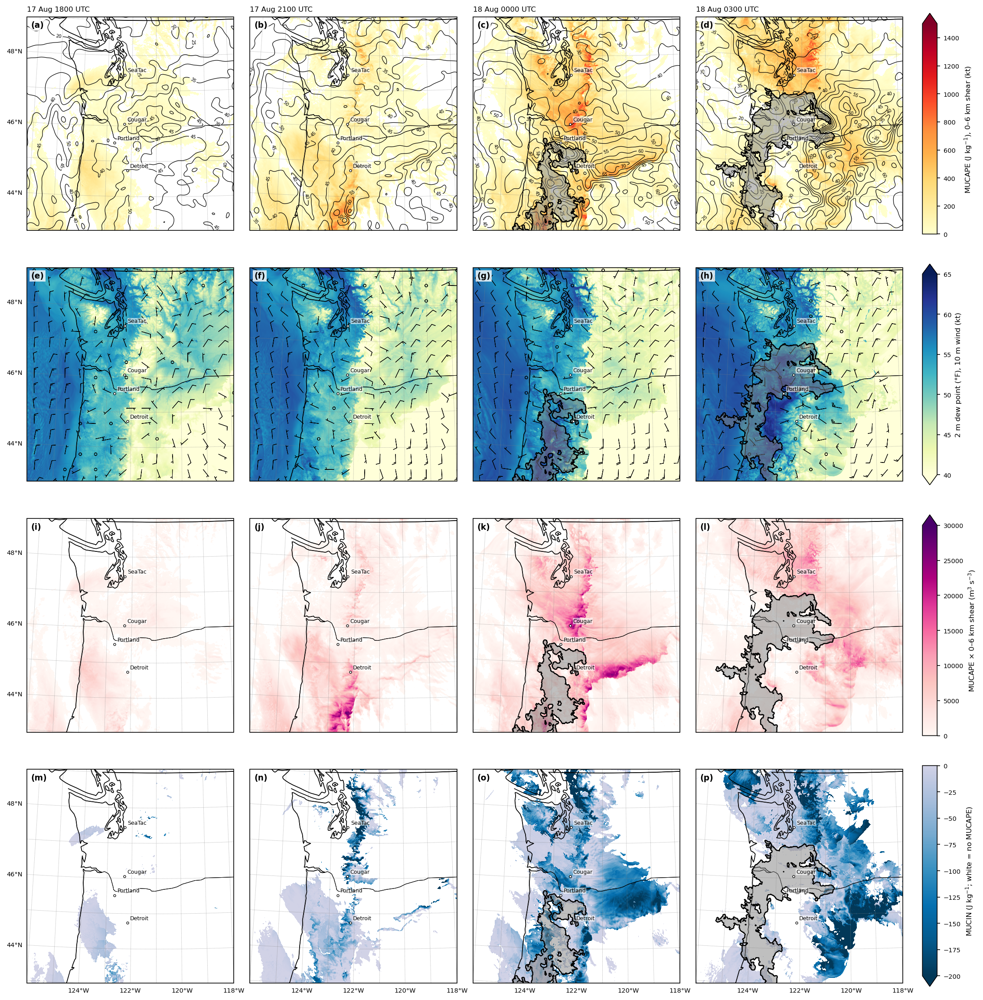

In [49]:
def environment_figure(times, panels, extent, name='fig1_environment'):
    # Rows = fields (ENV_PANELS), columns = times (ENV_TIMES); one colorbar per row on the right.
    times = [pd.Timestamp(t) for t in times]
    proj = ccrs.LambertConformal(central_longitude=-121, central_latitude=45.66, standard_parallels=(30, 60))
    nrows, ncols = len(panels), len(times)
    aspect = (extent[3] - extent[2]) / ((extent[1] - extent[0]) * np.cos(np.deg2rad(np.mean(extent[2:]))))
    fig, axes = plt.subplots(nrows, ncols, subplot_kw={'projection': proj}, squeeze=False, layout='constrained',
                             figsize=(ENV_PANEL_W * ncols + 1.0, ENV_PANEL_W * aspect * nrows + 0.3))
    for c, t in enumerate(times):
        f = compute_env_fields(t)
        sj, si = extent_slices(f['lat'], f['lon'], extent)
        lat, lon = f['lat'][sj, si], f['lon'][sj, si]
        trk = load_track_mask(t)
        for r, p in enumerate(panels):
            ax = axes[r, c]
            setup_map(ax, extent, label_left=(c == 0), label_bottom=(r == nrows - 1))
            data = f[p['field']][sj, si]
            if 'mask_below' in p:
                data = np.ma.masked_less(data, p['mask_below'])
            ax.pcolormesh(lon, lat, data, cmap=p['cmap'], vmin=p['vmin'], vmax=p['vmax'],
                          transform=PC, shading='auto', rasterized=True, zorder=1)
            if p.get('contour'):
                cf = gaussian_filter(f[p['contour']][sj, si], p.get('contour_smooth', 6))
                step = p.get('contour_step', 2)
                levels = p.get('contour_levels')
                if levels is None:
                    levels = np.arange(np.floor(np.nanmin(cf) / step) * step, np.nanmax(cf) + step, step)
                cs = ax.contour(lon, lat, cf, levels=levels, colors='k', linewidths=0.6, transform=PC, zorder=5)
                ax.clabel(cs, fontsize=5, fmt='%d', inline_spacing=1)
            if p.get('barbs'):
                s = (slice(None, None, ENV_BARB_SKIP), slice(None, None, ENV_BARB_SKIP))
                u, v = f[p['barbs'][0]][sj, si], f[p['barbs'][1]][sj, si]
                ax.barbs(lon[s], lat[s], u[s], v[s], length=4.5, linewidth=0.5, transform=PC, zorder=8)
            if p.get('quiver'):
                s = (slice(None, None, ENV_BARB_SKIP), slice(None, None, ENV_BARB_SKIP))
                u, v = f[p['quiver'][0]][sj, si], f[p['quiver'][1]][sj, si]
                qv = ax.quiver(lon[s], lat[s], u[s], v[s], transform=PC, scale=p.get('quiver_scale', 1500),
                               width=0.004, zorder=8)
                if c == ncols - 1 and p.get('quiver_key'):
                    ax.quiverkey(qv, 0.80, 1.04, p['quiver_key'], str(p['quiver_key']), labelpos='W',
                                 fontproperties={'size': 7})
            draw_track(ax, trk)
            plot_cities(ax, extent, fontsize=6, cities=ENV_CITIES)
            if r == 0:
                ax.set_title(f'{t:%d %b %H%M} UTC', loc='left', fontsize=8)
            panel_label(ax, r * ncols + c)
    for r, p in enumerate(panels):
        sm = ScalarMappable(norm=mcolors.Normalize(p['vmin'], p['vmax']), cmap=p['cmap'])
        cb = fig.colorbar(sm, ax=axes[r, :], orientation='vertical', shrink=0.9, aspect=15, pad=0.01,
                          extend=p.get('extend', 'neither'))
        cb.set_label(p['label'], fontsize=8)
        cb.ax.tick_params(labelsize=7)
    finish(fig, name)


environment_figure(ENV_TIMES, ENV_PANELS, ENV_EXTENT)

## Figure 1.5: WRF soundings

Skew-T profiles from the 1.33 km WRF at a site and time per panel, each with a hodograph inset. Edit `SOUNDINGS` to change sites or times; times must be on the hour (hourly WRF output).

Detroit, OR 17/2100Z: grid point 44.736, -122.154; MUCAPE 393, shear 48 kt, SRH3 174
Cougar, WA 18/0000Z: grid point 46.051, -122.306; MUCAPE 860, shear 46 kt, SRH3 180
SeaTac, WA 18/0300Z: grid point 47.454, -122.303; MUCAPE 471, shear 35 kt, SRH3 164
saved publication_figures\fig1p5_wrf_soundings.png
saved publication_figures\fig1p5_wrf_soundings.pdf


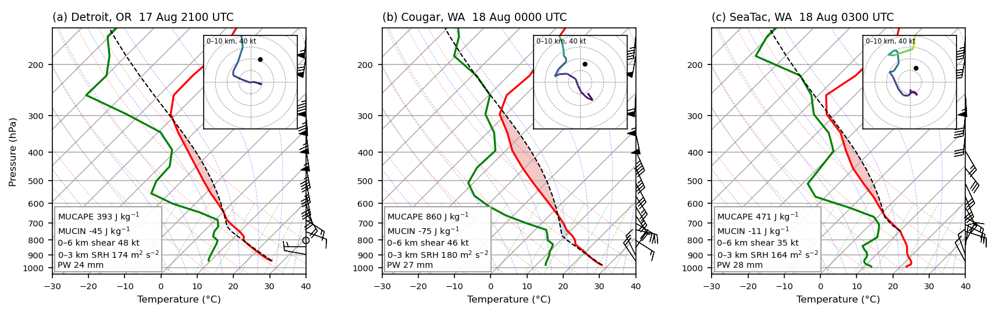

In [25]:
SOUNDINGS = [
    dict(name='Detroit, OR', time='2024-08-17 21:00', lat=44.7349, lon=-122.1512),
    dict(name='Cougar, WA', time='2024-08-18 00:00', lat=46.0519, lon=-122.3019),
    dict(name='SeaTac, WA', time='2024-08-18 03:00', lat=47.4489, lon=-122.3094),
]
SOUNDING_BOX = 0              # average over a (2n+1) x (2n+1) block of grid points (0 = nearest point only)
SOUNDING_PTOP = 150           # hPa
SOUNDING_TRANGE = (-30, 40)   # deg C at the bottom of the plot
SOUNDING_HODO_RANGE = 40      # kt
SOUNDING_HODO_TOP = 10000     # m AGL plotted on the hodograph
SOUNDING_PANEL_W = 4.5        # inches per panel

_PROFILE_CACHE = {}


def wrf_profile(t, lat, lon, box=0):
    # Column at the grid point nearest (lat, lon), optionally block-averaged: p (hPa), T/Td (C), u/v (kt), z AGL (m).
    key = (pd.Timestamp(t), lat, lon, box)
    if key not in _PROFILE_CACHE:
        with Dataset(WRF_FILES[pd.Timestamp(t)]) as nc:
            x, y = wrf.ll_to_xy(nc, lat, lon, meta=False)
            col = lambda a: np.asarray(a)[..., y - box:y + box + 1, x - box:x + box + 1].mean(axis=(-1, -2))
            p = col(getvar(nc, 'pressure', meta=False))
            T = col(getvar(nc, 'tc', meta=False))
            Td = col(getvar(nc, 'td', meta=False))
            uv = col(getvar(nc, 'uvmet', units='kt', meta=False))
            z = col(getvar(nc, 'z', meta=False)) - col(getvar(nc, 'ter', meta=False))
            glat, glon = col(getvar(nc, 'lat', meta=False)), col(getvar(nc, 'lon', meta=False))
        _PROFILE_CACHE[key] = dict(p=p, T=T, Td=Td, u=uv[0], v=uv[1], z=z, lat=float(glat), lon=float(glon))
    return _PROFILE_CACHE[key]


def sounding_figure(soundings, name='fig1p5_wrf_soundings'):
    n = len(soundings)
    fig = plt.figure(figsize=(SOUNDING_PANEL_W * n, SOUNDING_PANEL_W * 1.2))
    gs = fig.add_gridspec(1, n, wspace=0.3)        # room for the wind barbs right of each panel
    barb_levels = np.arange(1000, SOUNDING_PTOP - 1, -50)
    for k, snd in enumerate(soundings):
        t = pd.Timestamp(snd['time'])
        pr = wrf_profile(t, snd['lat'], snd['lon'], SOUNDING_BOX)
        p, T, Td = pr['p'] * units.hPa, pr['T'] * units.degC, pr['Td'] * units.degC
        u, v, z = pr['u'] * units.knot, pr['v'] * units.knot, pr['z'] * units.m

        skew = SkewT(fig, subplot=gs[0, k], rotation=45)
        skew.plot_dry_adiabats(linewidth=0.5, alpha=0.3)
        skew.plot_moist_adiabats(linewidth=0.5, alpha=0.3)
        skew.plot_mixing_lines(linewidth=0.5, alpha=0.3)
        skew.plot(p, T, 'r', linewidth=1.6)
        skew.plot(p, Td, 'g', linewidth=1.6)

        # most-unstable parcel (matches the MUCAPE in Figure 1)
        _, mu_T, mu_Td, idx = mpcalc.most_unstable_parcel(p, T, Td)
        prof = mpcalc.parcel_profile(p[idx:], mu_T, mu_Td).to('degC')
        skew.plot(p[idx:], prof, 'k', linewidth=1, linestyle='--')
        skew.shade_cape(p[idx:], T[idx:], prof, alpha=0.25)
        skew.shade_cin(p[idx:], T[idx:], prof, Td[idx:], alpha=0.25)

        bi = [int(np.argmin(np.abs(pr['p'] - lev))) for lev in barb_levels if pr['p'][0] >= lev]
        skew.plot_barbs(p[bi], u[bi], v[bi], length=6, linewidth=0.6)

        skew.ax.set_ylim(1050, SOUNDING_PTOP)
        skew.ax.set_xlim(*SOUNDING_TRANGE)
        skew.ax.tick_params(labelsize=7)
        skew.ax.set_xlabel('Temperature (\u00b0C)', fontsize=8)
        skew.ax.set_ylabel('Pressure (hPa)' if k == 0 else '', fontsize=8)
        skew.ax.set_title(f"({LETTERS[k]}) {snd['name']}  {t:%d %b %H%M} UTC", loc='left', fontsize=9)

        # indices
        mucape, mucin = mpcalc.most_unstable_cape_cin(p, T, Td)
        ushr, vshr = mpcalc.bulk_shear(p, u, v, height=z, depth=6 * units.km)
        rm, _, _ = mpcalc.bunkers_storm_motion(p, u, v, z)
        _, _, srh3 = mpcalc.storm_relative_helicity(z, u, v, depth=3 * units.km, storm_u=rm[0], storm_v=rm[1])
        pw = mpcalc.precipitable_water(p, Td).to('mm')
        txt = (f"MUCAPE {mucape.m:.0f} J kg$^{{-1}}$\nMUCIN {mucin.m:.0f} J kg$^{{-1}}$\n"
               f"0–6 km shear {np.hypot(ushr, vshr).to('knot').m:.0f} kt\n"
               f"0–3 km SRH {srh3.m:.0f} m$^2$ s$^{{-2}}$\nPW {pw.m:.0f} mm")
        skew.ax.text(0.02, 0.02, txt, transform=skew.ax.transAxes, fontsize=7, va='bottom', ha='left', zorder=20,
                     bbox=dict(facecolor='white', edgecolor='0.6', alpha=0.9, pad=2))
        print(f"{snd['name']} {t:%d/%H%MZ}: grid point {pr['lat']:.3f}, {pr['lon']:.3f}; "
              f"MUCAPE {mucape.m:.0f}, shear {np.hypot(ushr, vshr).to('knot').m:.0f} kt, SRH3 {srh3.m:.0f}")

        # hodograph inset, colored by height AGL
        ax_h = inset_axes(skew.ax, width='38%', height='38%', loc='upper right', borderpad=0.6)
        ax_h.set_facecolor('white')
        h = Hodograph(ax_h, component_range=SOUNDING_HODO_RANGE)
        h.add_grid(increment=10, linewidth=0.4)
        keep = pr['z'] <= SOUNDING_HODO_TOP
        h.plot_colormapped(u[keep], v[keep], z[keep], cmap='viridis', linewidth=1.5)
        ax_h.plot(rm[0].to('knot').m, rm[1].to('knot').m, 'ko', markersize=3)
        ax_h.set_xticklabels([]); ax_h.set_yticklabels([])
        ax_h.tick_params(length=0)
        ax_h.text(0.03, 0.97, f'0–{SOUNDING_HODO_TOP / 1000:.0f} km, {SOUNDING_HODO_RANGE} kt', transform=ax_h.transAxes,
                  fontsize=5.5, va='top')
    finish(fig, name)


sounding_figure(SOUNDINGS)

## Radar + storm report figures (shared)

`follow_extent(t0, t1)` rebuilds the moving box from `radar_animations/follow` (KRTX, 21–04Z) and returns the union
of the boxes the GIF frames showed between `t0` and `t1`. Pass an explicit `[W, E, S, N]` instead to override it.

In [26]:
RADARS = ['KRTX', 'KLGX', 'KATX']
SCAN_ALIGN = 'start'          # 'start' or 'center': which scan in each bin is shown
SCAN_TOL_MIN = 5              # max minutes between the target time and the scan used
DEALIAS = False               # region-based velocity dealiasing (Py-ART)
RADAR_RENDER = 'image'        # 'image': sweep gridded to RADAR_GRID_DEG, drawn with imshow (fast)
                              # 'pcolormesh': Py-ART's exact gate polygons (about 5x slower to draw/save)
RADAR_GRID_DEG = 0.004        # ~400 m, finer than a printed panel resolves
REFL_KW = dict(field='reflectivity', sweep=0, cmap='pyart_NWSRef', vmin=-20, vmax=75,
               label='Reflectivity (dBZ)')
VEL_KW = dict(field='velocity', sweep=1, cmap='pyart_NWSVel', vmin=-30, vmax=30,
              label='Radial velocity (m s$^{-1}$)')
CC_KW = dict(field='cross_correlation_ratio', sweep=0, cmap='pyart_Carbone42', vmin=0, vmax=1.0,
             label='Correlation coefficient')
RADAR_PANEL_W = 2.4           # inches per panel
BLOCK_GAP = 0.06              # gap between stacked row blocks (fraction of a block's height), holds the divider

# Report markers: high-contrast shapes that stay visible on both the reflectivity and velocity colormaps
REPORT_STYLE = {
    'Hail': dict(marker='^', s=45, facecolor='black', edgecolor='white', linewidth=0.8),
    'Wind': dict(marker='s', s=35, facecolor='black', edgecolor='white', linewidth=0.8),
}
LABEL_REPORTS = False         # small HHMM label next to each report

# radar_animations/follow settings (radar_analysis.ipynb, cell 5)
FOLLOW = dict(station='KRTX', start=datetime(2024, 8, 17, 21, 0), end=datetime(2024, 8, 18, 4, 0),
              lat_min=43.5, lat_max=44.5, lon_min=-123.5, lon_max=-121.5,
              lat_rate=0.0425, lon_rate=0.0072)

In [27]:
def radar_file_table(radar_dir=RADAR_DIR):
    rows = []
    for f in glob(os.path.join(radar_dir, '*_V06')):         # skips *_V06_MDM
        b = os.path.basename(f)
        rows.append(dict(station=b[:4], time=datetime.strptime(b[4:19], '%Y%m%d_%H%M%S'), path=f))
    return pd.DataFrame(rows).sort_values('time').reset_index(drop=True)


RADAR_FILES = radar_file_table()
_RADAR_CACHE = {}


def read_radar(path, extent):
    # Only the sweeps the figures use, with range gates cut at the farthest extent corner (much faster to
    # read, draw and save). Kept in memory, so re-running a figure cell skips the Level II decoding.
    key = (path, tuple(extent))
    if key not in _RADAR_CACHE:
        sweeps = sorted({kw['sweep'] for kw in (REFL_KW, VEL_KW, CC_KW)})
        radar = pyart.io.read_nexrad_archive(path, scans=sweeps, include_fields=[
            kw['field'] for kw in (REFL_KW, VEL_KW, CC_KW)])
        rlat, rlon = radar.latitude['data'][0], radar.longitude['data'][0]
        corners = [(la, lo) for la in extent[2:] for lo in extent[:2]]
        max_range = 1.05 * max(111e3 * np.hypot(la - rlat, (lo - rlon) * np.cos(np.deg2rad(rlat))) for la, lo in corners)
        n = int(np.searchsorted(radar.range['data'], max_range)) + 1
        if n < radar.ngates:
            radar.range['data'] = radar.range['data'][:n]
            for fld in radar.fields.values():
                fld['data'] = fld['data'][:, :n]
            radar.ngates = n
            radar.init_gate_x_y_z()
            radar.init_gate_longitude_latitude()
            radar.init_gate_altitude()
        _RADAR_CACHE[key] = radar, sweeps
    return _RADAR_CACHE[key]


def follow_extent(t0, t1, fl=FOLLOW):
    # Union of the follow-GIF boxes for frames with scan times in [t0, t1].
    frames = RADAR_FILES[(RADAR_FILES.station == fl['station']) &
                         (RADAR_FILES.time >= fl['start']) & (RADAR_FILES.time <= fl['end'])].reset_index(drop=True)
    idx = frames.index[(frames.time >= t0) & (frames.time <= t1)]
    i0, i1 = idx.min(), idx.max()
    return [round(min(fl['lon_min'] + i0 * fl['lon_rate'], fl['lon_min'] + i1 * fl['lon_rate']), 2),
            round(max(fl['lon_max'] + i0 * fl['lon_rate'], fl['lon_max'] + i1 * fl['lon_rate']), 2),
            round(min(fl['lat_min'] + i0 * fl['lat_rate'], fl['lat_min'] + i1 * fl['lat_rate']), 2),
            round(max(fl['lat_max'] + i0 * fl['lat_rate'], fl['lat_max'] + i1 * fl['lat_rate']), 2)]


def choose_scan(target, extent, radar='nearest'):
    # Scan nearest target within SCAN_TOL_MIN, from a fixed station or the station nearest the extent center.
    if radar == 'nearest':
        clat, clon = np.mean(extent[2:]), np.mean(extent[:2])
        stations = sorted(RADARS, key=lambda s: np.hypot(RADAR_SITES[s][0] - clat,
                                                         (RADAR_SITES[s][1] - clon) * np.cos(np.deg2rad(clat))))
    else:
        stations = [radar]
    for stn in stations:
        cand = RADAR_FILES[RADAR_FILES.station == stn]
        if cand.empty:
            continue
        dt = (cand.time - target).abs()
        if dt.min() <= pd.Timedelta(minutes=SCAN_TOL_MIN):
            return cand.loc[dt.idxmin()]
    return None


_IMG_CACHE = {}


def sweep_image(radar, sweep, field, extent, grid_deg=None, max_gap_deg=0.03):
    # Nearest-gate value on a regular lon/lat grid over extent; cells > max_gap_deg from any gate are masked.
    grid_deg = grid_deg or RADAR_GRID_DEG
    key = (id(radar), sweep, field, tuple(extent), grid_deg)
    if key not in _IMG_CACHE:
        sl = radar.get_slice(sweep)
        coslat = np.cos(np.deg2rad(np.mean(extent[2:])))
        tree = cKDTree(np.column_stack([radar.gate_longitude['data'][sl].ravel() * coslat,
                                        radar.gate_latitude['data'][sl].ravel()]))
        glon = np.arange(extent[0], extent[1] + grid_deg, grid_deg)
        glat = np.arange(extent[2], extent[3] + grid_deg, grid_deg)
        gx, gy = np.meshgrid(glon * coslat, glat)
        dist, idx = tree.query(np.column_stack([gx.ravel(), gy.ravel()]), distance_upper_bound=max_gap_deg)
        vals = np.ma.masked_invalid(np.ma.asarray(radar.fields[field]['data'][sl]).ravel())
        ok = np.isfinite(dist)
        img = np.ma.masked_all(gx.size)
        img[ok] = vals[idx[ok]]
        h = grid_deg / 2
        _IMG_CACHE[key] = img.reshape(gx.shape), [glon[0] - h, glon[-1] + h, glat[0] - h, glat[-1] + h]
    return _IMG_CACHE[key]


def plot_radar_panel(ax, radar, sweeps, kw, extent, grid_deg=None):
    sweep = sweeps.index(kw['sweep'])         # index within the trimmed volume
    field = kw['field']
    if field == 'velocity' and DEALIAS:
        if 'velocity_dealiased' not in radar.fields:
            radar.add_field('velocity_dealiased', pyart.correct.dealias_region_based(radar, vel_field='velocity'))
        field = 'velocity_dealiased'
    if RADAR_RENDER == 'image':
        img, img_extent = sweep_image(radar, sweep, field, extent, grid_deg)
        ax.imshow(img, origin='lower', extent=img_extent, transform=PC, cmap=kw['cmap'],
                  vmin=kw['vmin'], vmax=kw['vmax'], interpolation='nearest', zorder=1)
    else:
        disp = pyart.graph.RadarMapDisplay(radar)
        disp.plot_ppi_map(field, sweep, ax=ax, vmin=kw['vmin'], vmax=kw['vmax'], cmap=kw['cmap'],
                          projection=PC, min_lon=extent[0], max_lon=extent[1], min_lat=extent[2], max_lat=extent[3],
                          colorbar_flag=False, title_flag=False, embellish=False, add_grid_lines=False,
                          lat_lines=None, lon_lines=None, raster=True)
    ax.set_extent(extent, crs=PC)
    return radar.fixed_angle['data'][sweep]


def plot_reports(ax, rpts, extent, label_w=22, label_h=8.5):
    # Markers, plus HHMM labels placed (in points on the page) at the first free spot: the four corners
    # around the marker, then further down the page, so labels never overlap each other.
    to_pt = 72 / ax.figure.dpi
    boxes = []                                 # placed labels as (x0, x1, y0, y1) in points
    for _, row in rpts.sort_values('datetime').iterrows():
        ax.scatter(row['lon'], row['lat'], transform=PC, zorder=12, **REPORT_STYLE[row['reporttype']])
        if not LABEL_REPORTS:
            continue
        px, py = ax.transData.transform((row['lon'], row['lat'])) * to_pt
        candidates = [(6, -4), (6, 4 + label_h), (-6 - label_w, -4), (-6 - label_w, 4 + label_h)]
        candidates += [(6, -4 - label_h * k) for k in range(1, 20)]
        for dx, dy in candidates:              # dx, dy: offset of the label's top-left corner
            box = (px + dx, px + dx + label_w, py + dy - label_h, py + dy)
            if not any(box[0] < b[1] and b[0] < box[1] and box[2] < b[3] and b[2] < box[3] for b in boxes):
                break
        boxes.append(box)
        ax.annotate(f"{row['datetime']:%H%M}", (row['lon'], row['lat']), xycoords=PC._as_mpl_transform(ax),
                    xytext=(dx, dy), textcoords='offset points', fontsize=5.5, zorder=12,
                    ha='left', va='top', bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=0.5))


def radar_report_figure(start, end, extent, name, radar='nearest', bin_minutes=30, per_row=None,
                        boxes=None, box_size=0.25, extra_cities=None):
    # Bins go left to right, per_row at a time. Each block of bins is a reflectivity row over a velocity row;
    # blocks are stacked and separated by a thick black line. boxes: {'HHMM': (lon, lat)} box centers.
    bins = pd.date_range(start, end, freq=f'{bin_minutes}min', inclusive='left')
    per_row = per_row or len(bins)
    nblocks = int(np.ceil(len(bins) / per_row))
    nrows, ncols = 2 * nblocks, per_row
    aspect = (extent[3] - extent[2]) / (extent[1] - extent[0])
    fig = plt.figure(layout='constrained',
                     figsize=(RADAR_PANEL_W * ncols + 1.0, (RADAR_PANEL_W * aspect * 2 + 0.5) * nblocks))
    # one subfigure per block (refl row + vel row) leaves a real gap between blocks for the divider line
    subfigs = fig.subfigures(nblocks, 1, squeeze=False, hspace=BLOCK_GAP)[:, 0]
    axes = np.vstack([sf.subplots(2, ncols, subplot_kw={'projection': PC}, squeeze=False) for sf in subfigs])
    in_box = reports[(reports.lon >= extent[0]) & (reports.lon <= extent[1]) &
                     (reports.lat >= extent[2]) & (reports.lat <= extent[3])]
    for ax in axes.flat:
        ax.set_visible(False)
    for k, b0 in enumerate(bins):
        blk, c = divmod(k, per_row)
        b1 = b0 + pd.Timedelta(minutes=bin_minutes)
        target = b0 if SCAN_ALIGN == 'start' else b0 + (b1 - b0) / 2
        if isinstance(radar, (list, tuple)):              # schedule: [(start time, station), ...]
            stn = [s for t0, s in sorted(radar) if pd.Timestamp(t0) <= target][-1]
        else:
            stn = radar
        scan = choose_scan(target, extent, stn)
        half = pd.Timedelta(minutes=bin_minutes) / 2       # each report goes to the panel nearest in time
        rpts = in_box[(in_box.datetime >= target - half) & (in_box.datetime < target + half)]
        radar_obj, sweeps = read_radar(scan.path, extent) if scan is not None else (None, None)
        box = (boxes or {}).get(f'{target:%H%M}')
        for i, kw in enumerate([REFL_KW, VEL_KW]):
            r = 2 * blk + i
            ax = axes[r, c]
            ax.set_visible(True)
            if radar_obj is not None:
                elev = plot_radar_panel(ax, radar_obj, sweeps, kw, extent)
                title = f"{scan.time:%H%M} UTC  {scan.station} {elev:.1f}\u00b0"
            else:
                title = f'{target:%H%M} UTC  (no scan)'
            if i == 0:
                ax.set_title(title, loc='left', fontsize=7)
            setup_map(ax, extent, label_left=(c == 0), label_bottom=(r == nrows - 1), detail=True)
            plot_cities(ax, extent, extra=extra_cities)
            plot_reports(ax, rpts, extent)
            plot_radar_sites(ax, extent)
            if box is not None:
                ax.add_patch(Rectangle((box[0] - box_size / 2, box[1] - box_size / 2), box_size, box_size,
                                       transform=PC, fill=False, edgecolor='black', linewidth=1.8, zorder=14))
            panel_label(ax, r * ncols + c, fontsize=8)
        print(f'{target:%H%M} panel (reports {target - half:%H%M}-{target + half:%H%M}): scan {scan.station + " " + format(scan.time, "%H%M%S") if scan is not None else None}, '
              f'{len(rpts)} reports')
    for r in range(nrows):
        kw = [REFL_KW, VEL_KW][r % 2]
        sm = ScalarMappable(norm=mcolors.Normalize(kw['vmin'], kw['vmax']), cmap=kw['cmap'])
        cb = subfigs[r // 2].colorbar(sm, ax=[a for a in axes[r, :] if a.get_visible()], orientation='vertical',
                                      shrink=0.9, aspect=15, pad=0.01)
        cb.set_label(kw['label'], fontsize=8)
        cb.ax.tick_params(labelsize=7)
    handles = [Line2D([], [], linestyle='none', markersize=6, marker=st['marker'], markerfacecolor=st['facecolor'],
                      markeredgecolor=st['edgecolor'], label=f'{kind} report') for kind, st in REPORT_STYLE.items()]
    subfigs[0].legend(handles=handles, loc='outside upper right', ncol=2, fontsize=7, frameon=False)
    # thick horizontal line centered in the gap between blocks
    if nblocks > 1:
        fig.canvas.draw()                     # subfigure positions are set at draw time
        h = fig.bbox.height
        for b in range(1, nblocks):
            y = (subfigs[b - 1].bbox.y0 + subfigs[b].bbox.y1) / 2 / h
            fig.add_artist(Line2D([0.01, 0.99], [y, y], transform=fig.transFigure, color='black', linewidth=3))
    finish(fig, name)

## Figure 2: Supercell phase (21–00 UTC)

extent: [-122.5, -121.5, 44.25, 45.5]
2130 panel (reports 2115-2145): scan KRTX 213053, 0 reports
2200 panel (reports 2145-2215): scan KRTX 215825, 0 reports
2230 panel (reports 2215-2245): scan KRTX 222808, 0 reports
2300 panel (reports 2245-2315): scan KRTX 225731, 0 reports
2330 panel (reports 2315-2345): scan KRTX 232915, 1 reports
0000 panel (reports 2345-0015): scan KRTX 000148, 2 reports
saved publication_figures\fig2_supercell_2130_0030.png
saved publication_figures\fig2_supercell_2130_0030.pdf


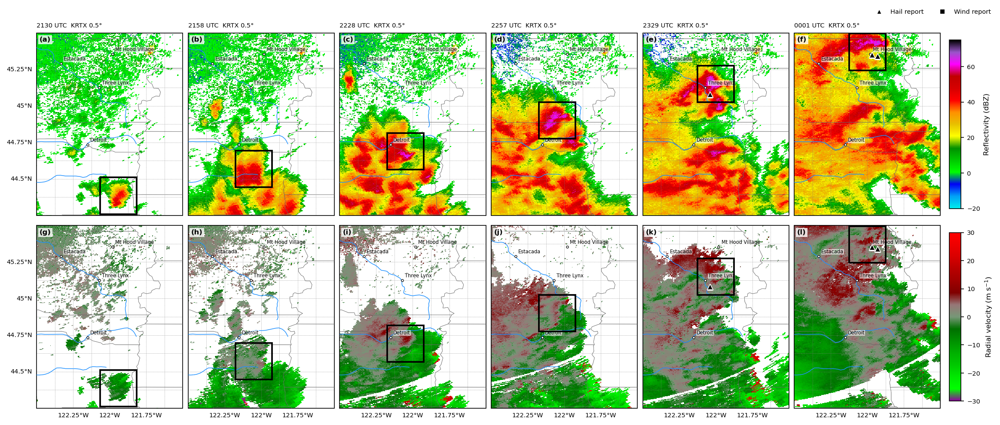

In [28]:
SC_START = datetime(2024, 8, 17, 21, 30)
SC_END = datetime(2024, 8, 18, 0, 30)
SC_EXTENT = [-122.5, -121.5, 44.25, 45.5]              # None -> follow-GIF coverage over [SC_START, SC_END]; or [W, E, S, N]
SC_RADAR = 'nearest'          # 'nearest' or a station code, e.g. 'KRTX'
SC_BIN_MINUTES = 30
SC_PER_ROW = None             # panels per row (None = all bins in one row)

# Solid black box around the supercell: panel time 'HHMM' -> box center (lon, lat); no box for times not listed.
# Linearly interpolated from (-121.92, 45.37) at 2130 to (-122.00, 45.42) at 0000 -- tune each one by hand.
SC_BOXES = {
    '2130': (-121.94, 44.385),
    '2200': (-122.05, 44.57),
    '2230': (-122.05, 44.69),
    '2300': (-122.05, 44.9),
    '2330': (-122, 45.15),
    '0000': (-122.000, 45.37),
}
SC_BOX_SIZE = 0.25            # box side length in degrees (both lon and lat)

sc_extent = SC_EXTENT or follow_extent(SC_START, SC_END)
print('extent:', sc_extent)
radar_report_figure(SC_START, SC_END, sc_extent, f'fig2_supercell_{SC_START:%H%M}_{SC_END:%H%M}',
                    radar=SC_RADAR, bin_minutes=SC_BIN_MINUTES, per_row=SC_PER_ROW,
                    boxes=SC_BOXES, box_size=SC_BOX_SIZE)

## Figure 3: MCS phase (00–04 UTC)

extent: [-124, -121, 45, 48]
0000 panel (reports 2345-0015): scan KRTX 000148, 2 reports
0030 panel (reports 0015-0045): scan KRTX 002856, 0 reports
0100 panel (reports 0045-0115): scan KRTX 010058, 1 reports
0130 panel (reports 0115-0145): scan KRTX 012730, 4 reports
0200 panel (reports 0145-0215): scan KRTX 015929, 0 reports
0230 panel (reports 0215-0245): scan KRTX 023220, 0 reports
0300 panel (reports 0245-0315): scan KRTX 025847, 0 reports
0330 panel (reports 0315-0345): scan KRTX 033038, 0 reports
saved publication_figures\fig3_mcs_0000_0400.png
saved publication_figures\fig3_mcs_0000_0400.pdf


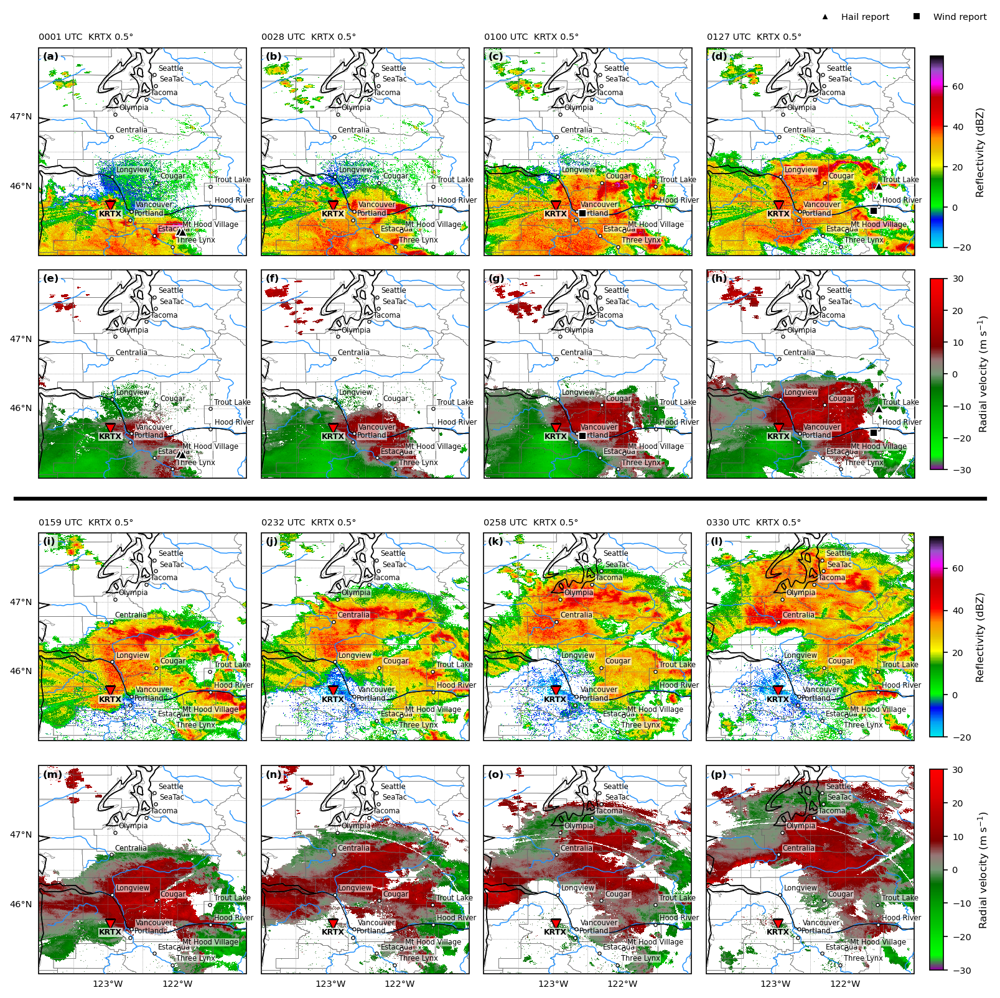

In [29]:
LATE_START = datetime(2024, 8, 18, 0, 0)
LATE_END = datetime(2024, 8, 18, 4, 0)
LATE_EXTENT = [-124, -121, 45, 48]         # None -> follow-GIF coverage over [LATE_START, LATE_END]; or [W, E, S, N]
LATE_RADAR = 'KRTX'           # 'nearest', a station code, or a schedule [(start time, station), ...]
                              # e.g. [(datetime(2024, 8, 18, 0, 0), 'KRTX'), (datetime(2024, 8, 18, 2, 0), 'KATX')]
LATE_BIN_MINUTES = 30
LATE_EXTRA_CITIES = {'Trout Lake': (45.9965, -121.5276), 'SeaTac': (47.4489, -122.3094),
                     'Cougar': (46.0519, -122.3019)}   # Figure 3 only
LATE_PER_ROW = 4              # 4 per row -> refl row, vel row, divider, refl row, vel row

late_extent = LATE_EXTENT or follow_extent(LATE_START, LATE_END)
print('extent:', late_extent)
radar_report_figure(LATE_START, LATE_END, late_extent, f'fig3_mcs_{LATE_START:%H%M}_{LATE_END:%H%M}',
                    radar=LATE_RADAR, bin_minutes=LATE_BIN_MINUTES, per_row=LATE_PER_ROW,
                    extra_cities=LATE_EXTRA_CITIES)

## Figure 4: Supercell close-up (reflectivity, velocity, correlation coefficient)

Rows are fields, columns are times. The default times are frames 3, 5, 7 and 9 of `radar_animations/tor`.

2218: scan KRTX 221805
2228: scan KRTX 222808
2238: scan KRTX 223811
2247: scan KRTX 224751
saved publication_figures\fig4_supercell_closeup_2218_2247.png
saved publication_figures\fig4_supercell_closeup_2218_2247.pdf


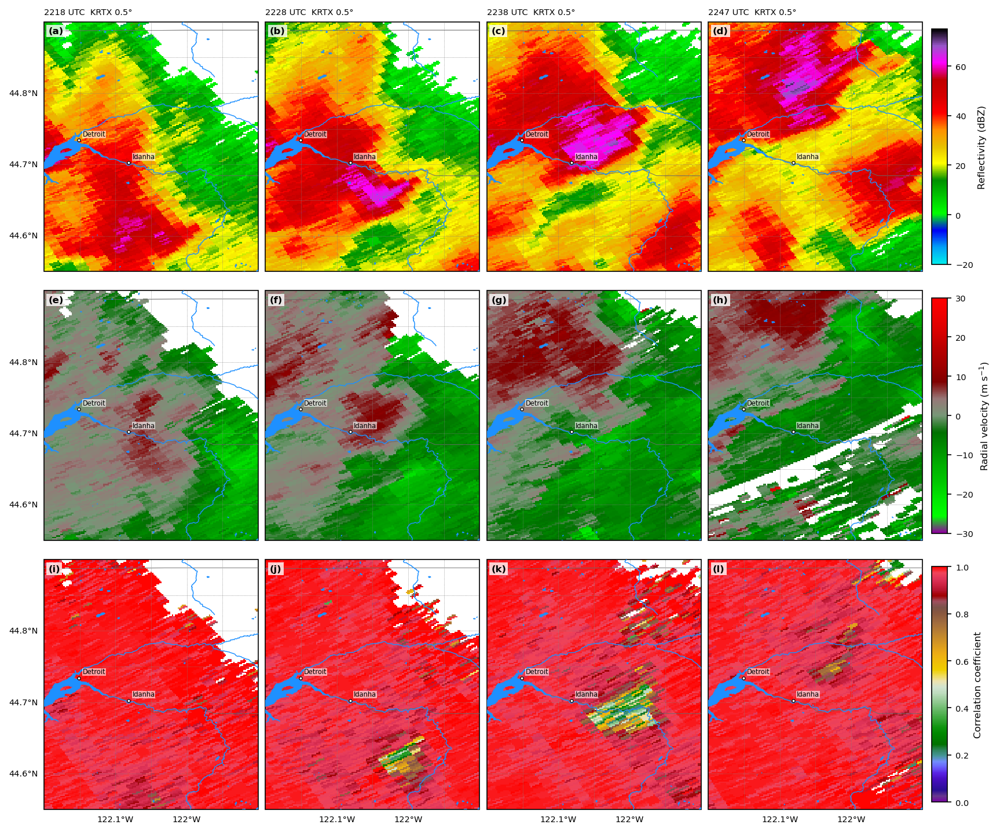

In [30]:
TOR_TIMES = ['2024-08-17 22:18', '2024-08-17 22:28', '2024-08-17 22:38', '2024-08-17 22:47']
TOR_EXTENT = [-122.2, -121.9, 44.55, 44.9]   # [W, E, S, N]
TOR_RADAR = 'KRTX'
TOR_FIELDS = [REFL_KW, VEL_KW, CC_KW]        # one row each
TOR_GRID_DEG = 0.002                         # finer display grid for the close zoom (~200 m)
TOR_PANEL_W = 2.6                            # inches per panel
TOR_EXTRA_CITIES = {'Idanha': (44.7024, -122.0813)}   # labels only on this figure (too close to Detroit elsewhere)
TOR_OSM_WATER = True                         # OpenStreetMap lakes + rivers (Detroit Lake etc.) instead of Natural Earth


def radar_fields_figure(times, extent, fields, name, radar='KRTX', grid_deg=None):
    # Rows = radar fields, columns = the scan nearest each time; one colorbar per row on the right.
    times = [pd.Timestamp(t) for t in times]
    nrows, ncols = len(fields), len(times)
    aspect = (extent[3] - extent[2]) / (extent[1] - extent[0])      # PlateCarree panels: degrees plotted 1:1
    fig, axes = plt.subplots(nrows, ncols, subplot_kw={'projection': PC}, squeeze=False, layout='constrained',
                             figsize=(TOR_PANEL_W * ncols + 1.0, TOR_PANEL_W * aspect * nrows + 0.4))
    for c, t in enumerate(times):
        scan = choose_scan(t, extent, radar)
        radar_obj, sweeps = read_radar(scan.path, extent) if scan is not None else (None, None)
        print(f'{t:%H%M}: scan {scan.station + " " + format(scan.time, "%H%M%S") if scan is not None else None}')
        for r, kw in enumerate(fields):
            ax = axes[r, c]
            if radar_obj is not None:
                elev = plot_radar_panel(ax, radar_obj, sweeps, kw, extent, grid_deg)
                title = f"{scan.time:%H%M} UTC  {scan.station} {elev:.1f}\u00b0"
            else:
                title = f'{t:%H%M} UTC  (no scan)'
            if r == 0:
                ax.set_title(title, loc='left', fontsize=7)
            setup_map(ax, extent, label_left=(c == 0), label_bottom=(r == nrows - 1), detail=True,
                      osm_water=TOR_OSM_WATER)
            plot_cities(ax, extent, extra=TOR_EXTRA_CITIES)
            plot_radar_sites(ax, extent)
            panel_label(ax, r * ncols + c, fontsize=8)
    for r, kw in enumerate(fields):
        sm = ScalarMappable(norm=mcolors.Normalize(kw['vmin'], kw['vmax']), cmap=kw['cmap'])
        cb = fig.colorbar(sm, ax=axes[r, :], orientation='vertical', shrink=0.9, aspect=15, pad=0.01)
        cb.set_label(kw['label'], fontsize=8)
        cb.ax.tick_params(labelsize=7)
    finish(fig, name)


radar_fields_figure(TOR_TIMES, TOR_EXTENT, TOR_FIELDS, f'fig4_supercell_closeup_{pd.Timestamp(TOR_TIMES[0]):%H%M}_{pd.Timestamp(TOR_TIMES[-1]):%H%M}',
                    radar=TOR_RADAR, grid_deg=TOR_GRID_DEG)